# 0. Pythonの特徴
* インタープリタ形式の高級言語で、C言語などの低級な言語と比べて、易しい
* AIやWebアプリなど制御対象が広いため、産業界での利用者も多く、ライブラリや解説が充実
* [（参考動画）Pythonのおすすめの参考書](https://www.youtube.com/watch?v=kUysq_MTMOA)

持ち込みPCにインストールする場合は、[Pythonの公式サイト](https://www.python.org/downloads/) からインストーラーをダウンロード。<br>
ターミナルで、<br>
　pip install jupyterlab<br>
と打つことにより、jupyter(エディター)もインストールできる。<br>
　jupyter lab<br>
と打てば、それを起動できる。（場合によっては、「python -m jupyter lab」で起動させる場合もある。）<br>

# 1. Pythonの基本文法　～まず体験してみよう！～
クリックして選択したセルの命令を、▶ボタン（または**Shift+Enter**）で実行します。

In [1]:
print("Hello, world!")

Hello, world!


In [2]:
1+1

2

In [3]:
3 * 10 / (7-2)

6.0

In [4]:
a = 3
print(a)

3


In [5]:
y = 2026
print("A happy new year", y)

A happy new year 2026


In [6]:
a = 3
a = 5
b = 1
print(a+b)

6


In [7]:
scores = [50, 55, 70, 65, 80]   # リスト型のデータを入力
print(scores[0])
print(scores[1])
print(scores[2])
print(scores[3])
print(scores[4])

50
55
70
65
80


In [8]:
len(scores)  # len()はリストの長さを返す関数

5

In [9]:
scores[0] = 100
print(scores)

[100, 55, 70, 65, 80]


In [10]:
for i in [0, 1, 2, 3, 4]:
    print(scores[i])

100
55
70
65
80


In [11]:
for i in range(5):
    print(scores[i])

100
55
70
65
80


In [12]:
year = 2026

if year < 2112:
    print("ドラえもんはまだ誕生していません。")
else:
    print("ドラえもんはもう誕生しています。")

ドラえもんはまだ誕生していません。


In [13]:
import math  # mathモジュールを読み込む
math.pi

3.141592653589793

In [14]:
format(math.pi, '.6f')  #小数点以下6位

'3.141593'

In [15]:
math.cos(math.pi)  # cos(π)の値を求める

-1.0

### (参考) Markdownとは？
Cellのモードとして**Code**ではなく**Markdown**を選択することで、レポートのように文章をまとめることもできます。

##### Markdownの文法まとめサイト：
* [Python初心者向けJupyter NotebookでセルにMarkdown記法で入力する方法](https://tonari-it.com/python-jupyter-notebook-markdown/)  
* [Markdown解説](https://home.hirosaki-u.ac.jp/jupyter/markdown/)  
* [Jupyter Notebook の操作：Markdown](https://rinsaka.com/python/intro/05-01-markdown.html)  
* [図解！Markdown記法の書き方を徹底解説](https://ai-inter1.com/markdown/)  
* [Markdown記法 サンプル集](https://qiita.com/tbpgr/items/989c6badefff69377da7)  
* [Jupyter NotebookでMarkdown作成](https://qiita.com/ttabata/items/5a4fb5949d196ec46884)





# 2. Pythonによる行列計算

## 2.0 使用するモジュールの準備

In [10]:
import numpy as np
from scipy.linalg import lu

## 2.1 ベクトルとベクトルとの内積

In [5]:
# 3次元ベクトルを２つ定義
u = np.array([ 0, 1, 2])
v = np.array([-1, 0, 1])

# 内積  = 0*(-1) + 1*0 + 2*1
np.dot(u, v)

2

In [6]:
# 実は @ でも内積が計算できる
u @ v

2

## 2.2 行列とベクトルとの積
* [行列とベクトルとの積の定義（動画 by Deep Insider）](https://www.youtube.com/embed/mq4eI8BoXZY?si=ZAjcmX44Gey7dI1a&amp;start=76)

In [8]:
# 2x2行列を定義
A = np.array([[0, 1], [-1, 1]])

# 2次元ベクトルを定義
w = np.array([1, 1])

# 行列とベクトルの積
np.dot(A, w)

array([1, 0])

In [9]:
# 演算子 @ による積（推奨）
A @ w

array([1, 0])

## 2.3 行列と行列との積

LU分解をするときの行の定数倍や、行の入れ替え等の意味がある行列を掛けよ！無駄な例は要らない！

In [48]:
A = np.array([[1, 2], [3, 4]]); A

array([[1, 2],
       [3, 4]])

In [49]:
U = np.array([[0, 1], [1, 0]]) #　この例では結果的に「 Lを左から掛ける = 1行目と2行目を入れ替える 」
U@A

array([[3, 4],
       [1, 2]])

## 2.4 逆行列

行列Lに逆行列L_invを掛けると単位行列となる

In [44]:
L = np.array([[1, 0], [0.5, 1]]); L

array([[1. , 0. ],
       [0.5, 1. ]])

In [45]:
L_inv = np.linalg.inv(L); L_inv

array([[ 1. ,  0. ],
       [-0.5,  1. ]])

In [46]:
L_inv @ L   # 左から掛けても単位行列となる

array([[1., 0.],
       [0., 1.]])

In [47]:
L @ L_inv   # 右から掛けても単位行列となる

array([[1., 0.],
       [0., 1.]])

## 2.5 逆行列による A x = u の解法（遅いので大規模行列では推奨しない）

In [94]:
A = np.array([[0, 1], [1, 1]]); A

array([[0, 1],
       [1, 1]])

In [97]:
u = np.array([ 1, 2])

# Aの逆行列を求める
A_inv = np.linalg.inv(A); print("A_inv =\n", A_inv)

# Ax=u の解を、x = A_inv u として求める
x = A_inv @ u; x

A_inv =
 [[-1.  1.]
 [ 1.  0.]]


array([1., 1.])

In [98]:
# 上の検算をしてみる
A @ x                # =u となっていることを確認

array([1., 2.])

## 2.6 行列のLU分解（= ガウスの掃き出し法）
A = LU  すなわち、LとUを掛けたら元に戻る

In [99]:
A = np.array([[0, 1], [1, 1]])

# LU分解
P, L, U = lu(A); print(P); print(L); print(U)

[[0. 1.]
 [1. 0.]]
[[1. 0.]
 [0. 1.]]
[[1. 1.]
 [0. 1.]]


In [100]:
P @ L @ U     # = A を確認

array([[0., 1.],
       [1., 1.]])

## 2.6 行列のLU分解（練習問題）

In [ ]:
# 次の行列AをLU分解せよ
A = np.array([[0, 2], [1, 0]])
lu(A)

## 2.7 ガウスの掃き出し法 (=LU分解)によるAx=uの解法（速いので推奨）

In [112]:
A = np.array([[0, 1], [1, 1]])

# LU分解
P, L, U = lu(A) # A = PLU を満たすことに注意

# PとLの逆行列を求めておく
P_inv = np.linalg.inv(P); print(P_inv)
L_inv = np.linalg.inv(L); print(L_inv)

[[0. 1.]
 [1. 0.]]
[[1. 0.]
 [0. 1.]]


In [115]:
# uを定義
u = np.array([ 1, 2])

# PLUx = u より Ux = L_inv P_inv u と問題を変換できる
u_new = L_inv @ P_inv @ u; print(u_new)

# 問題は U x = u_new へと変換された 
print(U)

[2. 1.]
[[1. 1.]
 [0. 1.]]


In [114]:
# U x = u_new は、対角化（正確には上半三角化）されているためすぐに解ける
np.linalg.solve(U, u_new)

array([1., 1.])

In [108]:
#（おまけ）実は最初からsolve()を使えば良い
np.linalg.solve(A, u) # solve()は中でLU分解（ガウスの掃き出し法）を行っているので、上と同じ計算をしたことになる

array([1., 1.])

## 2.8 ガウスの掃き出し法（練習問題；鶴亀算の例）

In [130]:
# 足は合計10本、鶴と亀は合計で4匹いる。それぞれ何匹か？
A = np.array([[2, 4], [1, 1]])
u = np.array([10, 4])

# A x = u を解けば、xが鶴と亀の頭数を表す

# もし全て鶴（鶴４匹で亀0匹）だったとすると...
x = np.array([4, 0])
A @ x

array([8, 4])

In [30]:
L = np.array([[1, -1], [0, 1]]) # Lを左に掛ける = 2行目を1行目から引いた

L@A

array([[1, 0],
       [0, 1]])

## 2.4 行列の固有値分解

かけたら戻ることを確認。上記2.3の例でも良いし。

## 2.5 色々な対角化１

## 2.6 行列分解の応用：神経細胞の同期発火を捉える

# 3. Pythonによる方程式f=0の解

複素関数は無、それ以外は全部含んでとにかく解く見通しを与える動画

## 3.1 解を求めよ（線形 / 多変数)

## 3.2 解を求めよ（非線形 / 1変数)

# 2. Pythonの組み込みデータ型
**int / float / bool / str / リスト / タプル / 辞書 / 集合**  
各データ型を１つ１つ理解することが、オブジェクト指向言語であるPythonを理解することになります。

## 2.2 float型（小数点）

In [28]:
(8 - 2)  / 2

3.0

In [29]:
type((8 - 2)  / 2)   # int同士であっても、割り算すると、floatへと型変換される

float

In [30]:
type(0.0)

float

In [31]:
type(0)

int

In [32]:
a = float(3)   # float関数によって、強制的にfloatへ型変換できる
print(a)
type(a)

3.0


float

In [33]:
a = int(0.0)
print(a)
type(a)

0


int

In [34]:
a = int(3.14)   # 切り捨てによって、intに型変換する
print(a)
type(a)

3


int

In [35]:
a = 3 + 1.5    # int型とfloat型を足すとfloat型となる
print(a)
type(a)

4.5


float

### (参考) 数値の指数表現
計算結果が指数表現されることも多いため、知っておくと良い

In [36]:
print(1.2e1) # = 1.2 * 10**1
print(1.2e0) # = 1.2 * 10**0
print(1.2e-1) # = 1.2 * 10**-1
print(1.2e-2) # = 1.2 * 10**-2

12.0
1.2
0.12
0.012


## 2.5 リスト型

In [58]:
scores = [50, 55, 70, 65, 80]

print(scores[0]) # 配列の参照
print(scores[1])
print(scores[2])
print(scores[3])
print(scores[4])

print('')

print(scores[-1]) # マイナスを付けると、末尾から数えた順番で参照できる
print(scores[-2])
print(scores[-3])
print(scores[-4])
print(scores[-5])

50
55
70
65
80

80
65
70
55
50


In [59]:
scores[2] = 71
scores

[50, 55, 71, 65, 80]

In [60]:
scores.append(100) # 末尾に付け加える
scores

[50, 55, 71, 65, 80, 100]

In [61]:
last = scores.pop() # 末尾から除く
print(last)
scores

100


[50, 55, 71, 65, 80]

In [62]:
scores.reverse() # 順序を逆にする
scores

[80, 65, 71, 55, 50]

In [63]:
scores.index(55) # 55のある位置を検索

3

In [64]:
del scores[2]   # 削除する
scores

[80, 65, 55, 50]

In [65]:
65 in scores         # 65は含まれるか？

True

In [66]:
scores2 = [10, 20, 30]
scores + scores2    # 連結する

[80, 65, 55, 50, 10, 20, 30]

In [67]:
len(scores + scores2)  # 配列の長さ

7

In [68]:
sorted(scores + scores2)  # 小さい順に並べ替える

[10, 20, 30, 50, 55, 65, 80]

### (参考) 内包形式によるリストの作成
長いリストは自動で作成したい。そのための便利な方法がある。

In [69]:
data1 = [1, 2, 4, 8, 16, 32, 64, 128]  # 2のn乗を手入力していくのは大変
print(data1)

data2 = []
for i in range(8):
    data2.append(2**i)                 # for文を使えば、自動化できるが、行数が多い
print(data2)

data3 = [2**n for n in range(8)]       # 内包形式なら、同じことが1行でできる
print(data3)

[1, 2, 4, 8, 16, 32, 64, 128]
[1, 2, 4, 8, 16, 32, 64, 128]
[1, 2, 4, 8, 16, 32, 64, 128]


## 2.7 辞書型

In [77]:
LLM1 = {"name": "GPT4", "developer": "OpenAI"} # キーワードと値のペアを保存する
LLM1

{'name': 'GPT4', 'developer': 'OpenAI'}

In [78]:
LLM1["name"]

'GPT4'

In [79]:
type(LLM1)

dict

In [80]:
LLM2 = {"name": "Llama3", "developer": "Facebook"}
LLM2["developer"] = "Elyza"  # 値を書き換えることが可能（リストと同様、タプルとは異なる）
LLM2

{'name': 'Llama3', 'developer': 'Elyza'}

In [81]:
for key, value in LLM1.items():
    print(key,"=======>>", value)

name =======>> GPT4
developer =======>> OpenAI


# 3. Pythonによる作図　～最小二乗法の図を美しく仕上げよう～
[Matplotlibに2通りある描画の流儀](https://moromisenpy.com/python_plot/)のうち、難しいオブジェクト指向（ax.~）は使わない、易しい方の流儀で統一します。

## 基本のグラフ（折れ線グラフ、散布図、ヒストグラム）

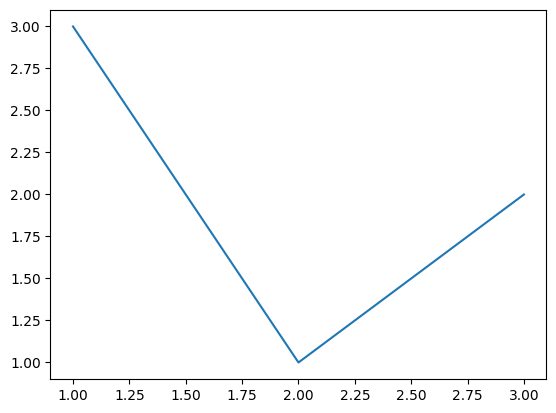

In [98]:
import matplotlib.pyplot as plt

# 折れ線グラフ
x = [1, 2, 3]
y = [3, 1, 2]
plt.plot(x, y)

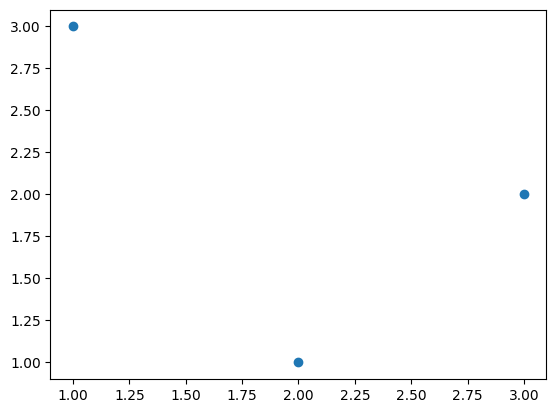

In [99]:
# 散布図
x = [1, 2, 3]
y = [3, 1, 2]
plt.scatter(x, y)

(array([1., 2., 1., 2., 1.]),
 array([0.5, 1.5, 2.5, 3.5, 4.5, 5.5]),
 <BarContainer object of 5 artists>)

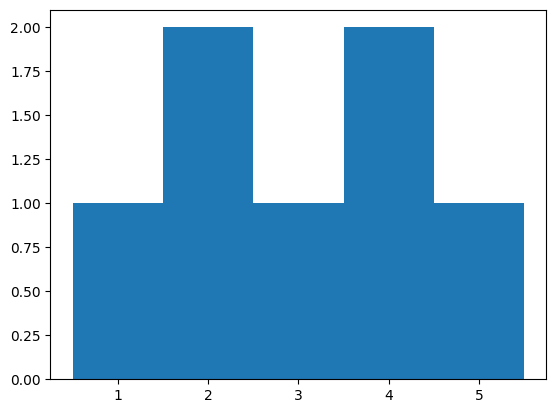

In [100]:
# ヒストグラム
z = [1, 2, 2, 3, 4, 4, 5]
plt.hist(z, range=(0.5, 5.5), bins=5)

## 最小二乗法　～散布図の真ん中を通る直線を引いてみよう！～

In [101]:
from sklearn.datasets import load_diabetes  # 使うライブラリをまとめて宣言しておく  # インストールするにはコンソールにて pip install scikit-learn
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

X = load_diabetes().data[:,2].reshape(-1,1)  # 今回はライブラリに付属するデータを利用する
Y = load_diabetes().target

model = LinearRegression()  # 線形回帰を行う
model.fit(X, Y)             # BMI値から糖尿病の進行を予測する

LinearRegression()

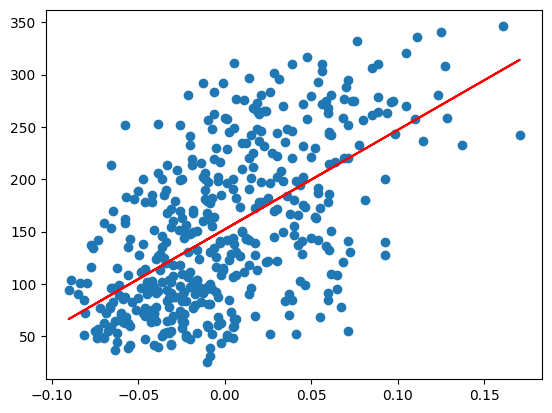

In [102]:
# ナイーブにプロット（あまり美しいとは言えないかも）
plt.scatter(X, Y)
plt.plot(X, model.predict(X), color='red')  # 回帰直線を赤線で加える

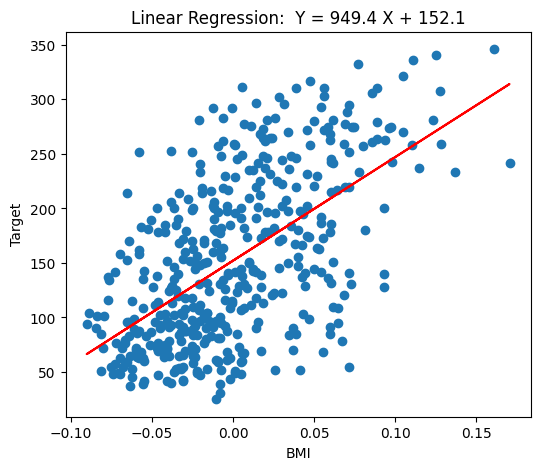

In [103]:
# より美しいプロットを試みる
plt.figure(figsize=(6, 5))                 # 縦横の比を指定する
plt.scatter(X,Y)
plt.plot(X, model.predict(X), color='red') # 回帰直線を赤線で加える
plt.xlabel('BMI'); plt.ylabel('Target')    # x軸とy軸にラベルを加える
txt = f'Linear Regression:  Y = {model.coef_[0]:.1f} X + {model.intercept_:.1f}'
plt.title(txt)                             # 表題として回帰直線の数式を加える
plt.show()

### **（演習課題）**上の最小二乗法の図をもっと美しくプロットせよ（下のリンク集を参考にせよ）

##### Matplotlibの解説サイト：
* [マーカー（打たれた点）のサイズを変えたい](http://www.maroon.dti.ne.jp/koten-kairo/works/fft/Section_PythonGraph/python_graph5.html)  
* [線の太さを変えたい](http://www.maroon.dti.ne.jp/koten-kairo/works/fft/Section_PythonGraph/python_graph4.html)  
* [x軸、y軸にラベル（説明）を加えたい（フォントサイズを必ず大きくせよ）](http://www.maroon.dti.ne.jp/koten-kairo/works/fft/Section_PythonGraph/python_graph6.html)  
* [[参考] グラフに数式を表示する方法（＄と＄でTexスタイルの数式を囲む）](https://www.useful-python.com/matplotlib-math/)  
* [[参考] 軸目盛りを調整したい](https://www.yutaka-note.com/entry/matplotlib_axis)  
* [[参考] ポリゴンや矢印などを足したい](https://pystyle.info/matplotlib-patches/)
* [[参考] 散布図以外にもヒストグラムや棒グラフも作図可能（subplotも）](https://ai-inter1.com/python-histogram/)

##### [参考] Matplotlib以外のPython解説サイト：
* [文字列の中に変数を入れたい：　txt = f'y = {model.coef_} x'](https://www.taklog.info/python-insert-variable-to-string)  
* [数字を出力する際に「桁数」を指定可能：　f'{model.intercept_:.1f}'](https://www.headboost.jp/python-print-handle-number-of-digits/)  
* [Matplotlibの代わりにSeabornを使っても作図できる：　import seaborn](https://blog.amedama.jp/entry/seaborn-plot)